# 01 · JNU-CTG · глубокая подготовка данных

## tl;dr

Новая отдельная серия для дородовых КТГ. Этот ноутбук проверяет весь архив, сохраняет первичный датасет и маски качества, фиксирует разбиение по пациенткам и экспортирует train-only подготовку. Основной исследовательский target — **бинарная экспертная оценка FIGO**, отдельный target — клинический исход neonatal_asphyxia. Модели здесь не обучаются.

### Выполненный результат

| Часть | Записей | Пациенток | Abnormal КТГ | Положительных пациенток по клиническому исходу |
|---|---:|---:|---:|---:|
| train | 12464 | 7564 | 53.82% | 55 |
| validation | 4165 | 2522 | 53.88% | 18 |
| test | 4140 | 2520 | 53.60% | 18 |

Проверены все 20769 записей. Два полностью отсутствующих FHR сохранены с явным флагом непригодности; неизвестные клинические метки не заменены нулями. 27 собственных дескрипторов + 27 масок пропуска дают 54 столбца табличного представления. STV/LTV производителя и опубликованные NetFea не подменяются собственными вычислениями. Возможность клинического применения не подтверждена.


## Context & Methods

**Решение:** подготовить проверяемую основу для дальнейшего обучения на дородовых цифровых КТГ. Сценарий приложения с неизвестным аппаратом остаётся отдельной задачей проверки измерений. Полный [план серии](ANALYSIS_PLAN.md) фиксирует следующие этапы.

### Key Assumptions

- Единица записи — 30-минутный FHR/UC сигнал при 4 Hz; единица независимости — patient_id с объединением точных повторов входного сигнала. Календарную хронологию из имён файлов не восстанавливаем.
- FIGO=0/1 — normal/abnormal. Suspect/pathologic отдельно не размечены; диагнозы и исходы не выводятся из этой метки. neonatal_asphyxia остаётся самостоятельной nullable целью.
- Основной X построен только из сигналов по фиксированным формулам. Все исходные клинические и опубликованные F_*/U_*/NetFea поля получают отдельные роли и не входят в первичный X. Их доступность и происхождение ещё нужно проверить.
- Сначала технический аудит всех файлов и фиксированные правила обработки, затем patient-grouped разбиение 60/20/20. Из 64 вариантов выбираем баланс только по группам, числу строк и меткам; признаки и модельные оценки не участвуют. После фиксации исследовательские распределения/корреляции и численная чувствительность — только train. Test не выбирает обработку.
- Оригинальные значения никогда не затираются. FHR=0/NaN/неположительное значение не является пригодным наблюдением. Дополнительная рабочая маска v1 использует **предварительный инженерный диапазон 30–240 BPM**. Это не клиническая норма и не доказанный диапазон конкретного прибора. Точки вне него сохранены в оригинале и с отдельным флагом; сравниваем с положительными исходными FHR. Резкие изменения внутри диапазона не удаляются автоматически.
- UC=0 сохраняется: по одному числу невозможно отличить отсутствие сокращений от отсутствия сигнала. UC имеет единицы прибора, не mmHg; уровень 100 не считается доказанным насыщением, поскольку исходные значения могут превышать 100.
- Основные дескрипторы используют наблюдавшиеся пригодные точки, без заполнения разрывов. Для signal-пути допускается отдельно помеченная линейная интерполяция внутренних пропусков ≤2 s, без краевой экстраполяции и без длинных мостов. Это инженерная версия, а не стандарт производителя.
- Ни диапазон, ни 80%-покрытие минутного окна, ни 2 s заполнения не подбираются по test или качеству классификатора. 80% — правило расчёта минутного дескриптора и дополнительный описательный срез качества; записи с меньшим покрытием не удаляются из датасета.
- Табличный median imputer + RobustScaler обучаются только на пригодном train; маски всех столбцов сохранены. В будущей CV надо заново fit **clone необученного шаблона внутри каждого fit-фолда**. Подготовленные масштабированные train-матрицы нельзя использовать как вход nested CV.
- Параметры стандартизации сигналов вычисляются только по пригодным наблюдениям train. Нормализованный числовой ноль в неиспользуемой точке всегда сопровождается маской; он не означает нормальную ЧСС.


In [3]:
from pathlib import Path
import sys,json,textwrap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.features.jnu_ctg_preparation import (SOURCE,PROCESSED,OUT,MODELS,prepare_all,FS,
    signal_masks,bounded_interpolation,FHR_ENGINEERING_RANGE)
sns.set_theme(style='whitegrid',font_scale=1.02)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',110)
def show_save(name):
    plt.gcf().savefig(OUT/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · первоисточник и полный запуск подготовки

[Официальный источник](https://zenodo.org/records/21800730), DOI 10.5281/zenodo.21800730. Исходные определения и лицензия находятся внутри скачанного архива; путь `data/external/jnu_ctg/1.0.0/`. MD5 сверяется с публикацией, имена и CRC всех waveform-файлов проверяются при чтении. Скачанный код не исполняется.

Первый запуск сканирует все сигналы; повторный использует кеш, только если совпадают исходный архив и реализация дескрипторов/масок. Большая memory-map матрица исходных сигналов лежит на диске; вычисления не требуют загрузки всего массива в память.


In [5]:
primary,balance,dictionary,normalization_issues,cross_flags=prepare_all()
original=pd.read_parquet(PROCESSED/'metadata_original.parquet')
clean=pd.read_parquet(PROCESSED/'metadata_clean.parquet')
features=pd.read_parquet(PROCESSED/'signal_features.parquet')
quality=pd.read_parquet(PROCESSED/'signal_quality.parquet')
signal_index=pd.read_parquet(PROCESSED/'signal_index.parquet')
signals=np.load(PROCESSED/'signals_original_float32.npy',mmap_mode='r')
contract=json.loads((PROCESSED/'feature_contract.json').read_text())
columns=contract['primary_features']
train=primary[primary.split=='train'].copy()
qtrain=quality.merge(train[['record_id','signal_row']],on='record_id',validate='one_to_one')
display(pd.Series(json.loads((OUT/'source_receipt.json').read_text()),name='source_receipt').to_frame())
print('Primary dataset:',primary.shape,'; original signal shape:',signals.shape)
display(pd.DataFrame({'environment_version':json.loads((OUT/'manifest.json').read_text())['environment']}))


Primary dataset: (20769, 39) ; original signal shape: (20769, 7200, 2)


,source_receipt
archive_md5,ac1cfcba2f1b3336596544211d776771
archive_sha256,6efe9ce43f5ef803eb4ef65c87892e1a768899ff3bb82de56c18c834d5e09a98
columns,215
doi,10.5281/zenodo.21800730
duplicate_headers,{}
patients,12606
rows,20769
source_definitions,README and LICENSE inside original archive; no downloaded code executed
source_url,https://zenodo.org/records/21800730
version,jnu_preparation_v1_20261017


,environment_version
joblib,1.6.0
nbformat,5.11.1
numpy,2.4.6
pandas,2.3.3
scikit-learn,1.9.1
scipy,1.17.1


### Структура повторных записей и роли полей

Все строки сохранены. patient_id даёт доступную группировку. Порядок строк и общий суффикс имён не доказывают порядок обследований; «первую по времени» запись сейчас выбрать нельзя. Постоянные клинические сведения проверены на противоречия внутри patient_id.

Исходные признаки F_STV/F_LTV не включаем только на основании названий. Для NetFea неизвестно, на каких данных обучался экстрактор; это отдельный риск утечки. Исходы родов и Апгар недоступны во время дородового предсказания. Бинарные признаки, порядковые баллы, числа событий, измерения и идентификаторы размечены в реестре типов отдельно.


,role,statistical_type,columns
0,delivery_or_postnatal_exclude,binary,38
1,delivery_or_postnatal_exclude,nominal_category,1
2,delivery_or_postnatal_exclude,numeric_measure_or_count,26
3,delivery_or_postnatal_exclude,ordinal_score,18
4,identifier,identifier,2
5,potential_covariate_timing_unverified,count,2
6,potential_covariate_timing_unverified,numeric_measure_or_count,4
7,published_feature_definition_or_fit_scope_unverified,published_numeric_definition_unverified,108
8,target_only,binary,2
9,timing_unverified_exclude,binary,9


,position,source_name,canonical_name,duplicate_source_header


,filename_audit
chronology_recoverable,False
decision,"Use explicit patient_id; prefix is record-unique, common suffix is not a reliable date"
parse_failures,0
unique_patient_ids,12606
unique_prefixes,20769
unique_suffixes,1


,column,patients_with_conflicting_values


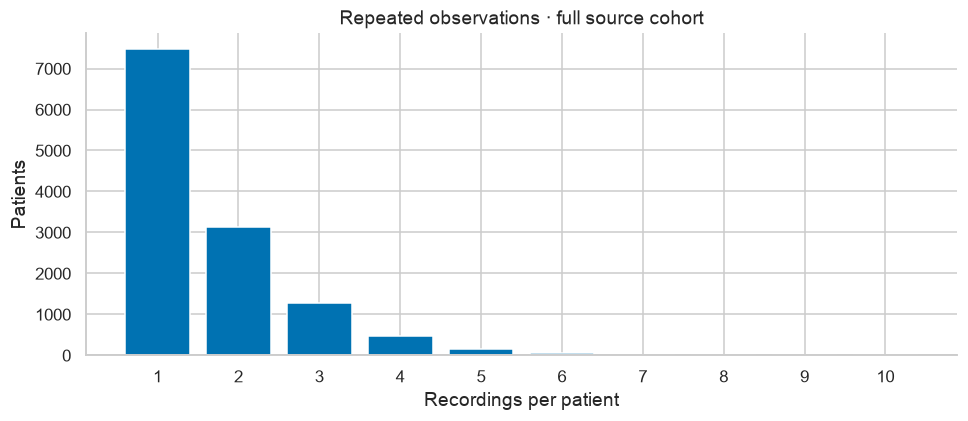

In [7]:
display(dictionary.groupby(['role','statistical_type']).size().rename('columns').reset_index())
display(pd.read_csv(OUT/'source_column_registry.csv').query('duplicate_source_header'))
display(pd.Series(json.loads((OUT/'filename_audit.json').read_text()),name='filename_audit').to_frame())
consistency=pd.read_csv(OUT/'patient_metadata_consistency.csv')
display(consistency[consistency.patients_with_conflicting_values>0])
counts=original.groupby('patient_id').size().value_counts().sort_index()
fig,ax=plt.subplots(figsize=(9,4));ax.bar(counts.index,counts.values,color='#0072b2')
ax.set(xlabel='Recordings per patient',ylabel='Patients',title='Repeated observations · full source cohort')
ax.set_xticks(counts.index);fig.tight_layout();show_save('01_patient_repeats.png')


### Пропуски, текстовые заглушки и клинические противоречия

Отсутствующее значение, строка «/» и число вне допустимого диапазона не означают здоровый исход. Некорректные числа превращаются в NaN только в очищенной копии; оригинал и причина сохранены. Для Апгар проверяем целочисленность, диапазон суммы 0–10 и компонентов 0–2. При полной записи проверяется сумма компонентов. Диагноз neonatal_asphyxia не переписывается по Апгар автоматически.

Получено 1259 записей журнала нормализации для 1041 record_id. У 7 записей от 5 patient_id положительная neonatal_asphyxia сочетается с Апгар >7 и на 1-й, и на 5-й минуте. Это требует проверки согласованности с описанием исхода, а не автоматической замены метки. До обучения на редкий клинический исход эти случаи нужно рассмотреть отдельно.

Структурные пропуски в поздних полях, например размерах дефекта плаценты, могут означать неприменимость. Их не заполняем общей медианой для дородовой модели: эти поля вообще не входят в основной X.


Logged normalizations: 1259 affected records: 1041


,column,reason,rows
41,placenta_surface_length_cm,non_numeric_or_sentinel,503
31,cervical_laceration_depth_cm,non_numeric_or_sentinel,157
49,third_stage_hr,non_numeric_or_sentinel,107
0,amniotic_fluid_volume_ml,non_numeric_or_sentinel,103
47,second_stage_hr,non_numeric_or_sentinel,87
37,membrane_defect_upper,non_numeric_or_sentinel,38
34,gestational_age,unparsed_gestation,38
46,postpartum_bleeding_2hr_ml,non_numeric_or_sentinel,26
33,first_stage_min,non_numeric_or_sentinel,20
51,total_labor_hr,non_numeric_or_sentinel,18


,records
check,
apgar_10min_component_sum_disagrees,25
apgar_1min_component_sum_disagrees,52
apgar_5min_component_sum_disagrees,21
asphyxia_positive_both_apgar_above_7_review_only,7
gravidity_above_20_review_only,6
parity_exceeds_gravidity,1


,record_id,column,raw_value,reason
906,16747_1_210208000001,apgar_1min_color,/,non_numeric_or_sentinel
907,35615_1_210208000001,apgar_1min_color,9,invalid_domain_or_noninteger
908,35616_1_210208000001,apgar_1min_color,9,invalid_domain_or_noninteger
909,16747_1_210208000001,apgar_1min_heart_rate,/,non_numeric_or_sentinel
910,16747_1_210208000001,apgar_1min_respiration,/,non_numeric_or_sentinel
911,24474_1_210208000001,apgar_1min_respiration,3,invalid_domain_or_noninteger
912,24475_1_210208000001,apgar_1min_respiration,3,invalid_domain_or_noninteger
913,24476_1_210208000001,apgar_1min_respiration,3,invalid_domain_or_noninteger


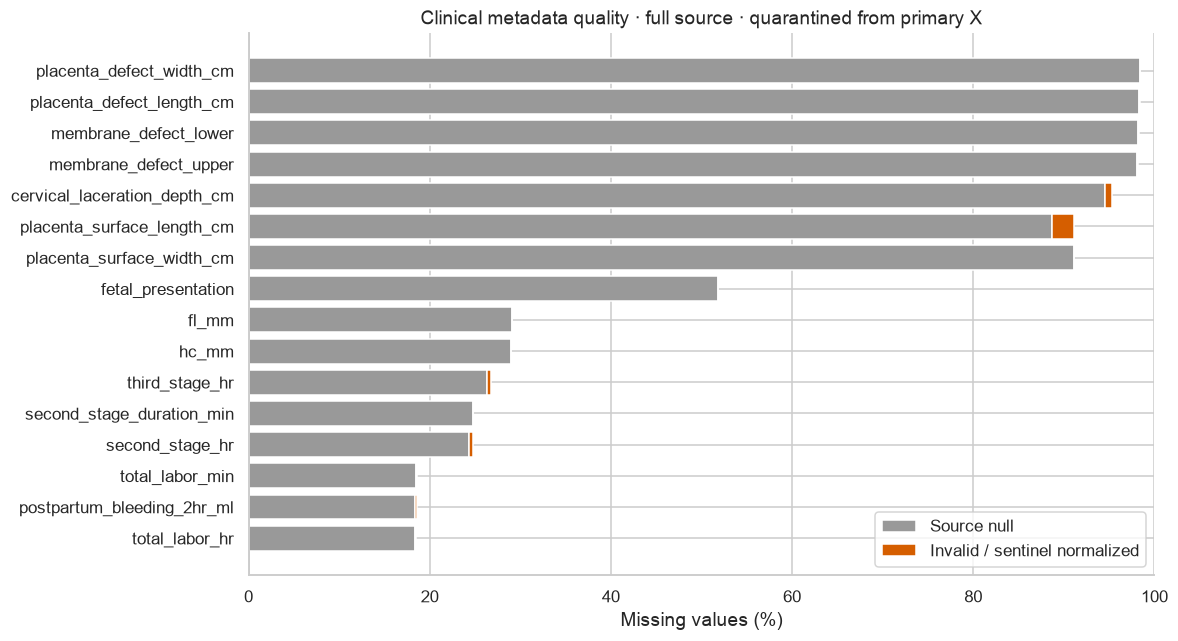

In [9]:
missing=pd.read_csv(OUT/'metadata_missingness.csv')
repairs=pd.read_csv(OUT/'metadata_normalization_summary.csv')
print('Logged normalizations:',len(normalization_issues),'affected records:',normalization_issues.record_id.nunique())
display(repairs.sort_values('rows',ascending=False).head(18))
display(cross_flags.groupby('check').size().rename('records').to_frame())
display(normalization_issues[normalization_issues.column.str.startswith('apgar_')].head(8))
top=missing.sort_values('clean_missing',ascending=False).head(16).sort_values('clean_missing')
fig,ax=plt.subplots(figsize=(11,6))
ax.barh(top.column,100*top.original_missing/len(original),label='Source null',color='#999999')
ax.barh(top.column,100*top.additional_missing/len(original),left=100*top.original_missing/len(original),label='Invalid / sentinel normalized',color='#d55e00')
ax.set(xlabel='Missing values (%)',title='Clinical metadata quality · full source · quarantined from primary X',xlim=(0,100));ax.legend()
fig.tight_layout();show_save('02_metadata_missingness.png')


## Results · качество всех сигналов и train-диагностика

Проверка формы/кодирования/точных дублей выполняется для всего источника как контроль целостности. Ниже распределения качества и примеры относятся к train. Рабочая маска отличается от наличия исходного положительного числа: диапазонный артефакт остаётся виден отдельно. Маски хранятся упакованными по битам; порядок и индексы документированы.

Нет автоматического удаления записи по доле пропусков. Полностью отсутствующий пригодный FHR даёт `primary_training_eligible=False` и должен приводить к отказу signal-модели. Даже для такого примера строки и исходные метки сохраняются, чтобы впоследствии показывать реальную долю отказов.


,source_integrity_check
records,20769
no_source_positive_FHR,2
no_analysis_valid_FHR,2
FHR_coverage_below_80pct,2019
records_with_range_flags,28
records_with_constant_FHR_runs_30s,3
records_with_UC_above_100_device_units,1292
exact_FHR_duplicate_records,2
exact_two_channel_duplicate_records,0


,count,mean,std,min,25%,50%,75%,max
fhr_longest_constant_valid_run_s,12464.0,5.362,3.551,1.75,4.00,5.00,6.00,332.250
fhr_fraction_in_constant_runs_30s,12464.0,0.000,0.003,0.00,0.00,0.00,0.00,0.315
uc_longest_constant_run_s,12464.0,48.558,105.826,1.75,12.25,20.75,36.25,1763.000


,hash_type,sha256,recordings,patients
0,fhr_sha256,19a9b0eb3572bcbee480f15089a756416b5ec8619f8f95fc78658f727be4fbf9,2,2


has_valid_fhr         ... clinical_outcome_training_eligible       
                    size    sum  ...                               size    sum
split                            ...                                          
test                4140   4138  ...                               4140   4124
train              12464  12464  ...                              12464  12430
validation          4165   4165  ...                               4165   4155

[3 rows x 6 columns]

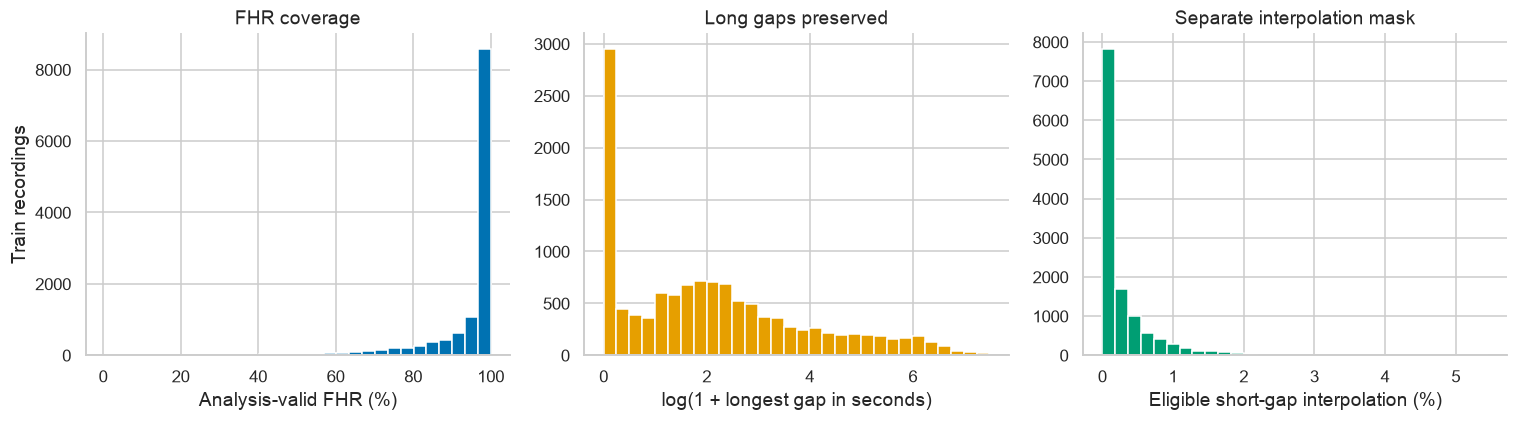

In [11]:
source_quality=pd.Series({
    'records':len(quality),
    'no_source_positive_FHR':int((quality.fhr_source_present_fraction==0).sum()),
    'no_analysis_valid_FHR':int((quality.fhr_observed_fraction==0).sum()),
    'FHR_coverage_below_80pct':int((quality.fhr_observed_fraction<.8).sum()),
    'records_with_range_flags':int((quality.fhr_range_flag_fraction>0).sum()),
    'records_with_constant_FHR_runs_30s':int((quality.fhr_longest_constant_valid_run_s>=30).sum()),
    'records_with_UC_above_100_device_units':int((features.uc_device_max>100).sum()),
    'exact_FHR_duplicate_records':int(signal_index.fhr_sha256.duplicated(keep=False).sum()),
    'exact_two_channel_duplicate_records':int(signal_index.waveform_sha256.duplicated(keep=False).sum())})
display(source_quality.to_frame('source_integrity_check'))
display(qtrain[['fhr_longest_constant_valid_run_s','fhr_fraction_in_constant_runs_30s','uc_longest_constant_run_s']].describe().T.round(3))
display(pd.read_csv(OUT/'exact_signal_duplicate_groups.csv'))
display(primary.groupby('split')[['has_valid_fhr','primary_training_eligible','clinical_outcome_training_eligible']].agg(['size','sum']))
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].hist(100*qtrain.fhr_observed_fraction,bins=30,color='#0072b2');axes[0].set(xlabel='Analysis-valid FHR (%)',ylabel='Train recordings',title='FHR coverage')
axes[1].hist(np.log1p(qtrain.fhr_longest_gap_s),bins=30,color='#e69f00');axes[1].set(xlabel='log(1 + longest gap in seconds)',title='Long gaps preserved')
axes[2].hist(100*qtrain.fhr_interpolated_fraction,bins=30,color='#009e73');axes[2].set(xlabel='Eligible short-gap interpolation (%)',title='Separate interpolation mask')
fig.tight_layout();show_save('03_train_signal_quality.png')


### Примеры исходного и пригодного FHR

Примеры выбраны по качеству сигнала в train: хорошее покрытие, наиболее длинный разрыв, больше диапазонных флагов. Метка FIGO не выбирает эти примеры. На графике показана рабочая маска без заполнения. Изолированный скачок не считается автоматически децелерацией или патологией; ошибки половинной/двойной частоты и примесь материнского ритма без дополнительных каналов достоверно исправить нельзя.

Длинные плато одинаковых FHR сохранены с отдельными показателями длины/доли. Это может быть удержание значения устройством, предобработка или реальная низкая вариабельность; удалять плато только по форме нельзя. `primary_training_eligible` означает минимальную вычислительную пригодность (есть хотя бы один пригодный FHR и известна метка), а не гарантию качества. Отдельный флаг покрытия ≥80% позволяет дальше сравнивать полную когорту и политику отказов; все случаи отказа должны учитываться в отчёте.


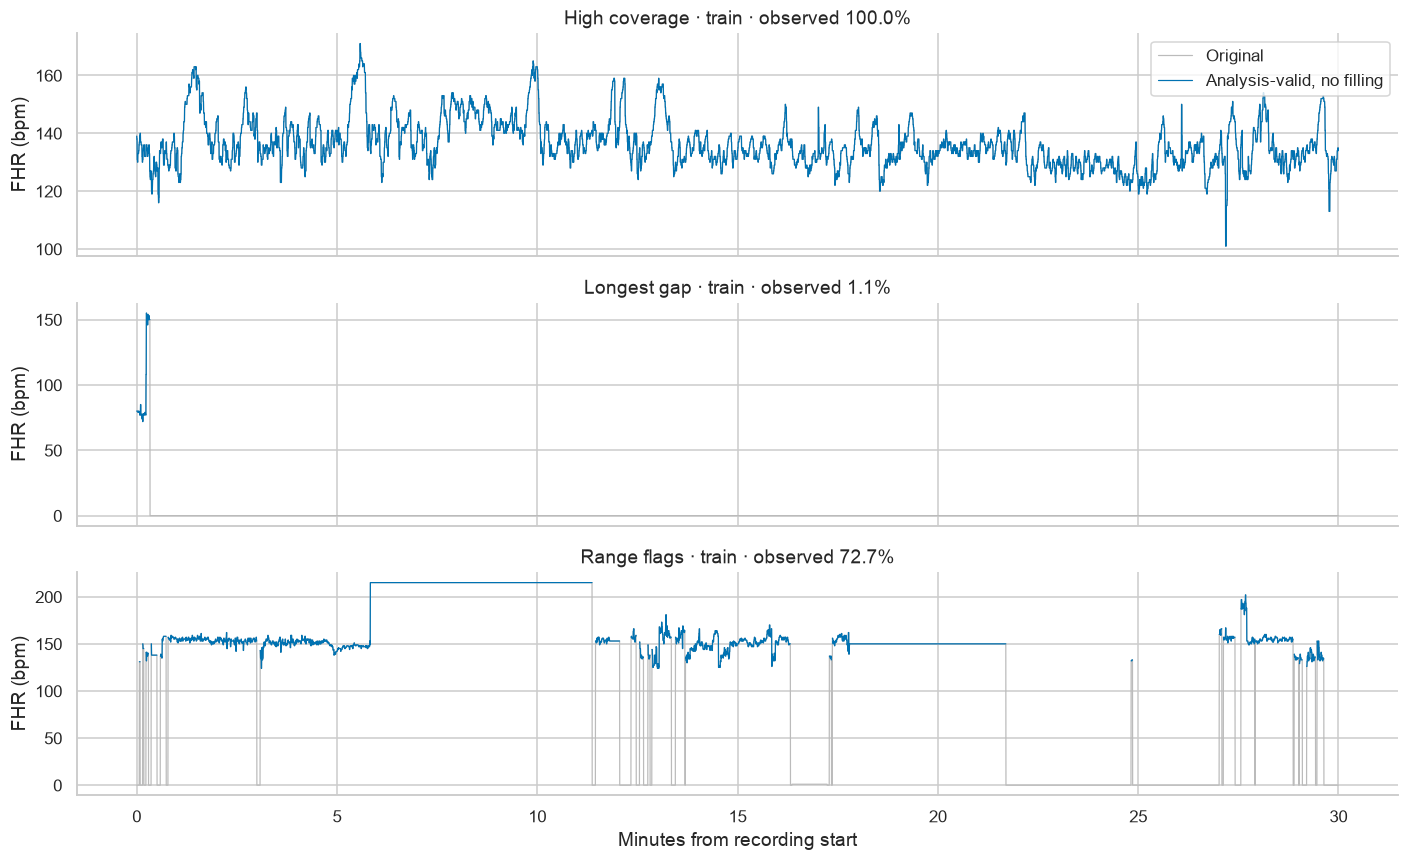

In [13]:
selected=[qtrain.sort_values('fhr_observed_fraction',ascending=False).iloc[0],
          qtrain.sort_values('fhr_longest_gap_s',ascending=False).iloc[0],
          qtrain.sort_values('fhr_range_flag_fraction',ascending=False).iloc[0]]
fig,axes=plt.subplots(3,1,figsize=(13,8),sharex=True)
for ax,row,title in zip(axes,selected,['High coverage','Longest gap','Range flags']):
    wave=np.asarray(signals[int(row.signal_row)]);masks,_=signal_masks(wave);time=np.arange(len(wave))/FS/60
    ax.plot(time,wave[:,0],color='#bbbbbb',lw=.8,label='Original')
    ax.plot(time,np.where(masks['fhr_observed'],wave[:,0],np.nan),color='#0072b2',lw=.8,label='Analysis-valid, no filling')
    ax.set(ylabel='FHR (bpm)',title=f'{title} · train · observed {row.fhr_observed_fraction:.1%}')
axes[0].legend(loc='upper right');axes[-1].set_xlabel('Minutes from recording start')
fig.tight_layout();show_save('04_train_signal_examples.png')


### Независимые единицы и баланс train/validation/test

Связанные patient_id и точные повторы FHR объединены в компоненты. Дубли не удаляются по меткам; конфликт записывается, все связанные строки остаются по одну сторону разбиения. SHA-256 выявляет точные повторы, но не доказывает отсутствие близких/перекрывающихся сигналов.

Сохраняем естественную долю классов: баланс означает сопоставимые пропорции, а не 50/50 через пересэмплирование. Веса `1 / число записей пациентки` позволяют дополнительно оценивать качество без преобладания часто обследованных пациенток. Дата обследования неизвестна, поэтому эти веса не разрешают усреднять будущие записи для сегодняшнего прогноза.


,split,records,patients,normal_records,abnormal_records,abnormal_record_fraction
0,train,12464,7564,5756,6708,0.5382
1,test,4140,2520,1921,2219,0.5360
2,validation,4165,2522,1921,2244,0.5388


,split,asphyxia_positive_records,asphyxia_positive_patients,asphyxia_known_patients,asphyxia_unknown_records,asphyxia_patient_prevalence
0,train,93,55,7541,34,0.00729
1,test,27,18,2513,14,0.00716
2,validation,34,18,2514,10,0.00716


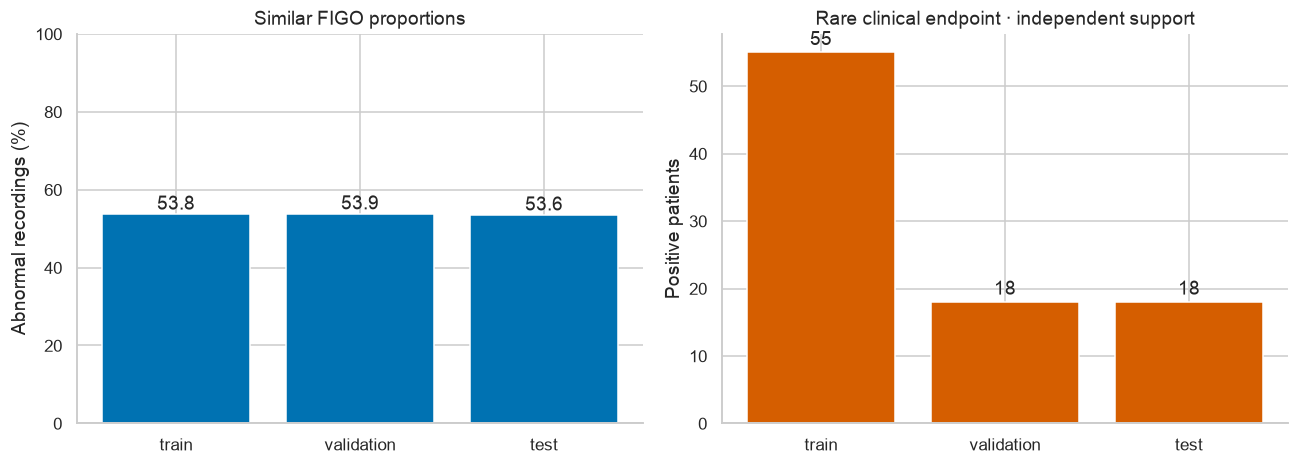

In [15]:
display(balance[['split','records','patients','normal_records','abnormal_records','abnormal_record_fraction']].round(4))
display(balance[['split','asphyxia_positive_records','asphyxia_positive_patients','asphyxia_known_patients','asphyxia_unknown_records','asphyxia_patient_prevalence']].round(5))
support=balance.set_index('split').loc[['train','validation','test']]
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
axes[0].bar(support.index,100*support.abnormal_record_fraction,color='#0072b2');axes[0].set(ylim=(0,100),ylabel='Abnormal recordings (%)',title='Similar FIGO proportions')
axes[1].bar(support.index,support.asphyxia_positive_patients,color='#d55e00');axes[1].set(ylabel='Positive patients',title='Rare clinical endpoint · independent support')
for ax,values in zip(axes,[100*support.abnormal_record_fraction,support.asphyxia_positive_patients]):
    for i,value in enumerate(values):ax.text(i,value+.02*max(values),f'{value:.1f}' if ax is axes[0] else str(int(value)),ha='center')
fig.tight_layout();show_save('05_split_support.png')


### Первичный X: 27 воспроизводимых дескрипторов

Среднее, медиана, стандартное отклонение, min/max, квантили, IQR и MAD для FHR и UC; соседние разности только между двумя пригодными соседними точками; разность медиан наблюдавшихся точек первых/последних 5 min; медиана минутных размахов при ≥80% наблюдений в минуте; собственная эпохальная RR-разность.

`project_rr_epoch_adjacent_abs_ms`: пересчёт 60000/FHR, 3.75-секундные эпохи с ≥80% наблюдений, абсолютная разность соседних эпох внутри минуты. Здесь нет подтверждённого исключения акцелераций/децелераций и истинных beat-to-beat RR. **Этот показатель не называется клиническим STV.** Минутный размах также не подменяет LTV прибора.

Общая доля качества, диапазонные/скачковые флаги и UC=0 находятся в отдельной таблице. Их включение в модель требует абляции: они могут отражать особенности аппарата и процесса записи.


,feature,unit,definition_version,allows_missing,source,not_vendor_metric
0,fhr_bpm_mean,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
1,fhr_bpm_median,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
2,fhr_bpm_std,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
3,fhr_bpm_min,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
4,fhr_bpm_max,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
5,fhr_bpm_q05,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
6,fhr_bpm_q25,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
7,fhr_bpm_q75,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
8,fhr_bpm_q95,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True
9,fhr_bpm_iqr,bpm,jnu_preparation_v1_20261017,True,observed raw signal,True


,feature,missing,zero,min,median,max
0,fhr_bpm_mean,0,0,96.4623,141.0600,184.9752
1,fhr_bpm_median,0,0,79.0000,140.0000,188.0000
2,fhr_bpm_std,0,0,1.6234,8.1382,42.0718
3,fhr_bpm_min,0,0,30.0000,110.0000,160.0000
4,fhr_bpm_max,0,0,127.0000,176.0000,240.0000
5,fhr_bpm_q05,0,0,49.0000,130.9500,169.0000
6,fhr_bpm_q25,0,0,75.0000,136.0000,181.0000
7,fhr_bpm_q75,0,0,105.0000,145.0000,215.0000
8,fhr_bpm_q95,0,0,127.0000,156.0000,234.0000
9,fhr_bpm_iqr,0,0,1.0000,9.0000,70.0000


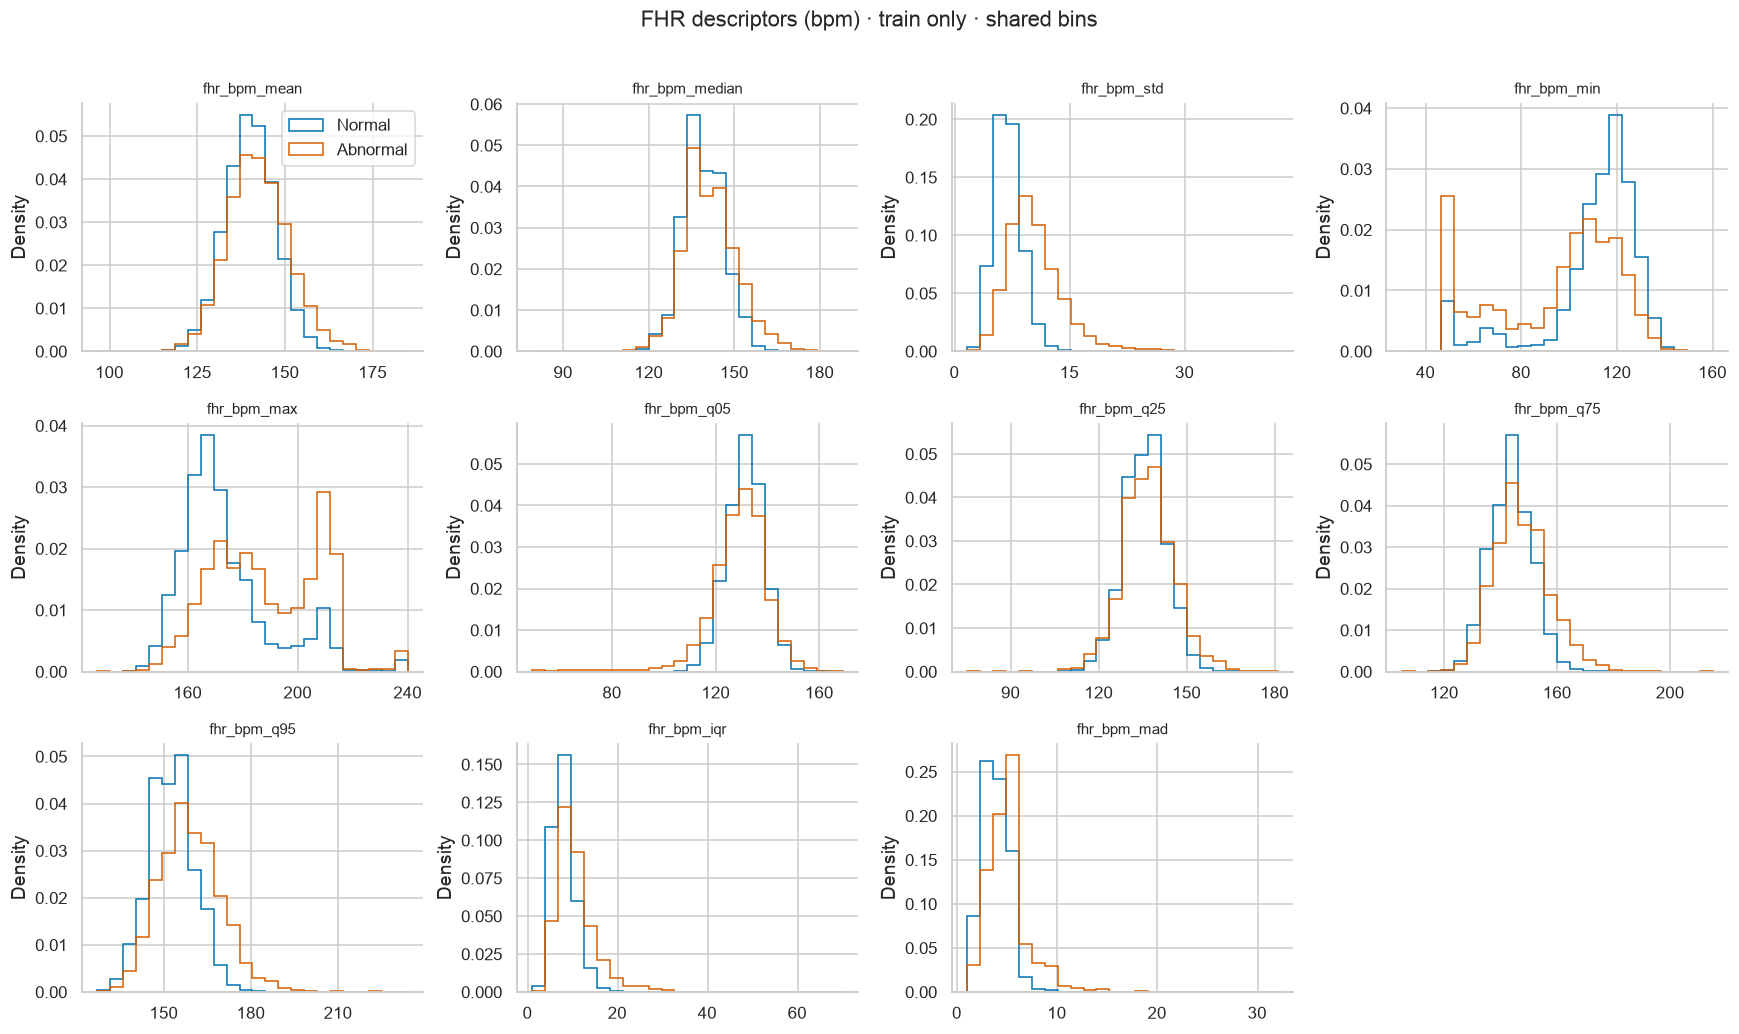

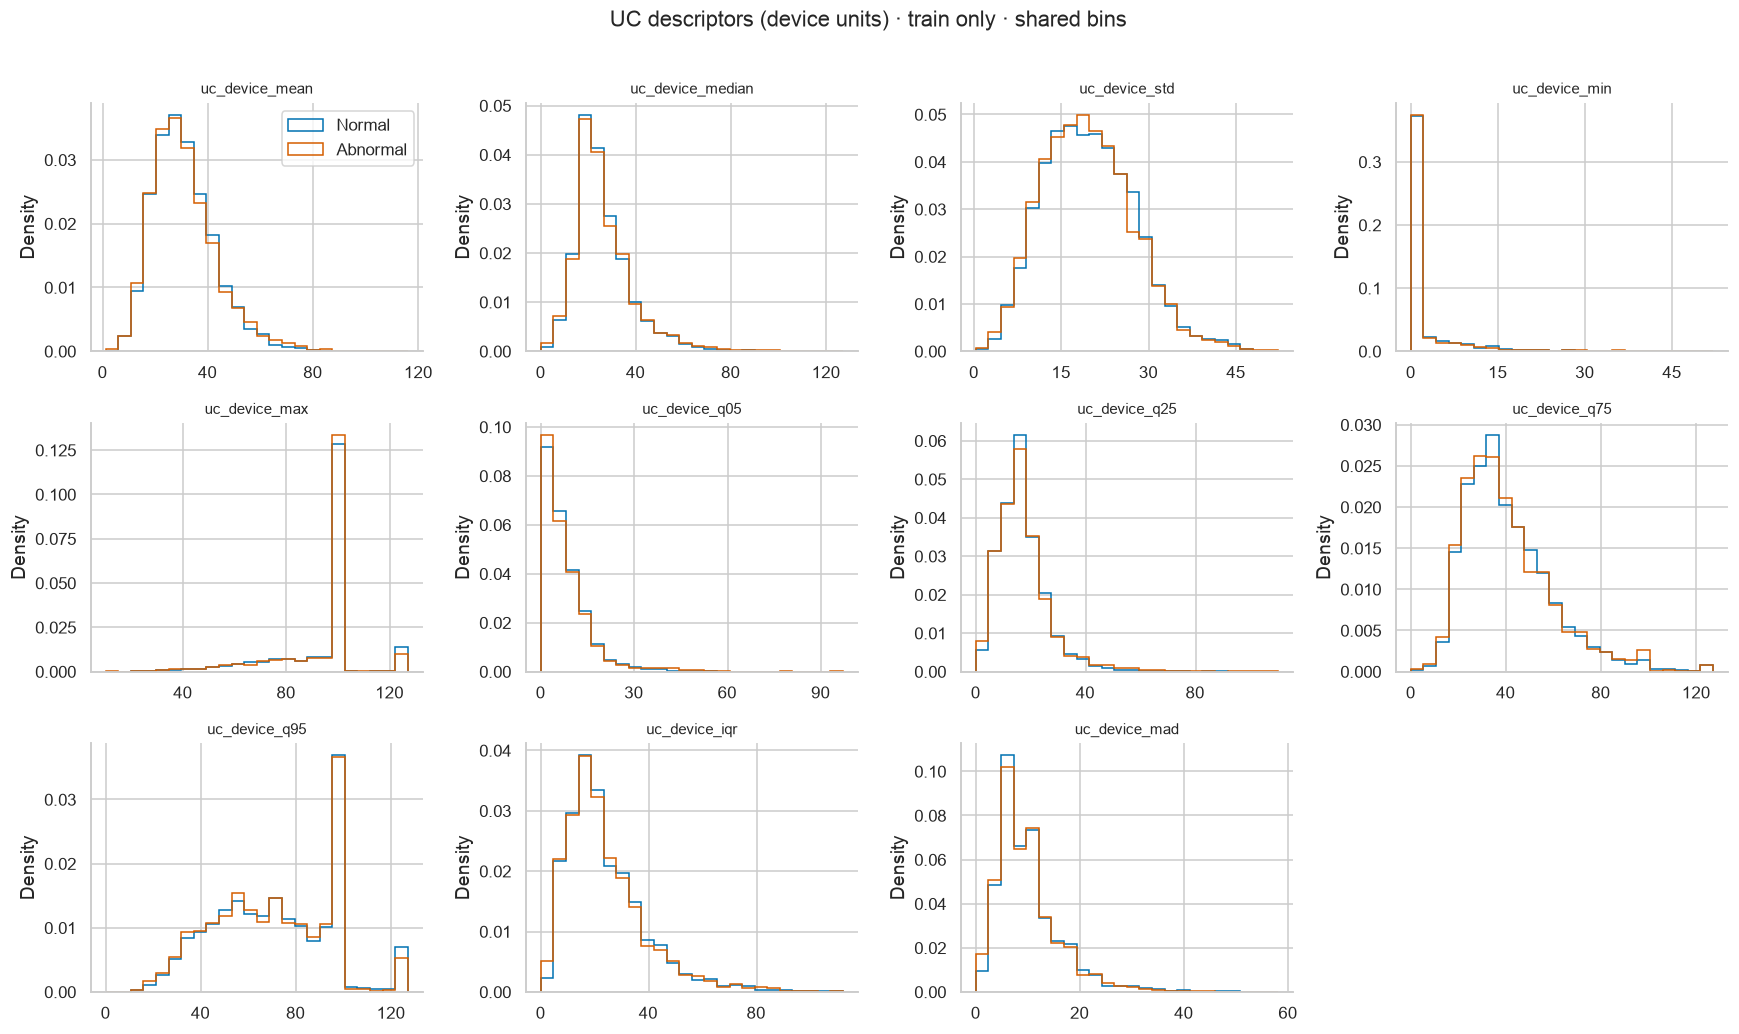

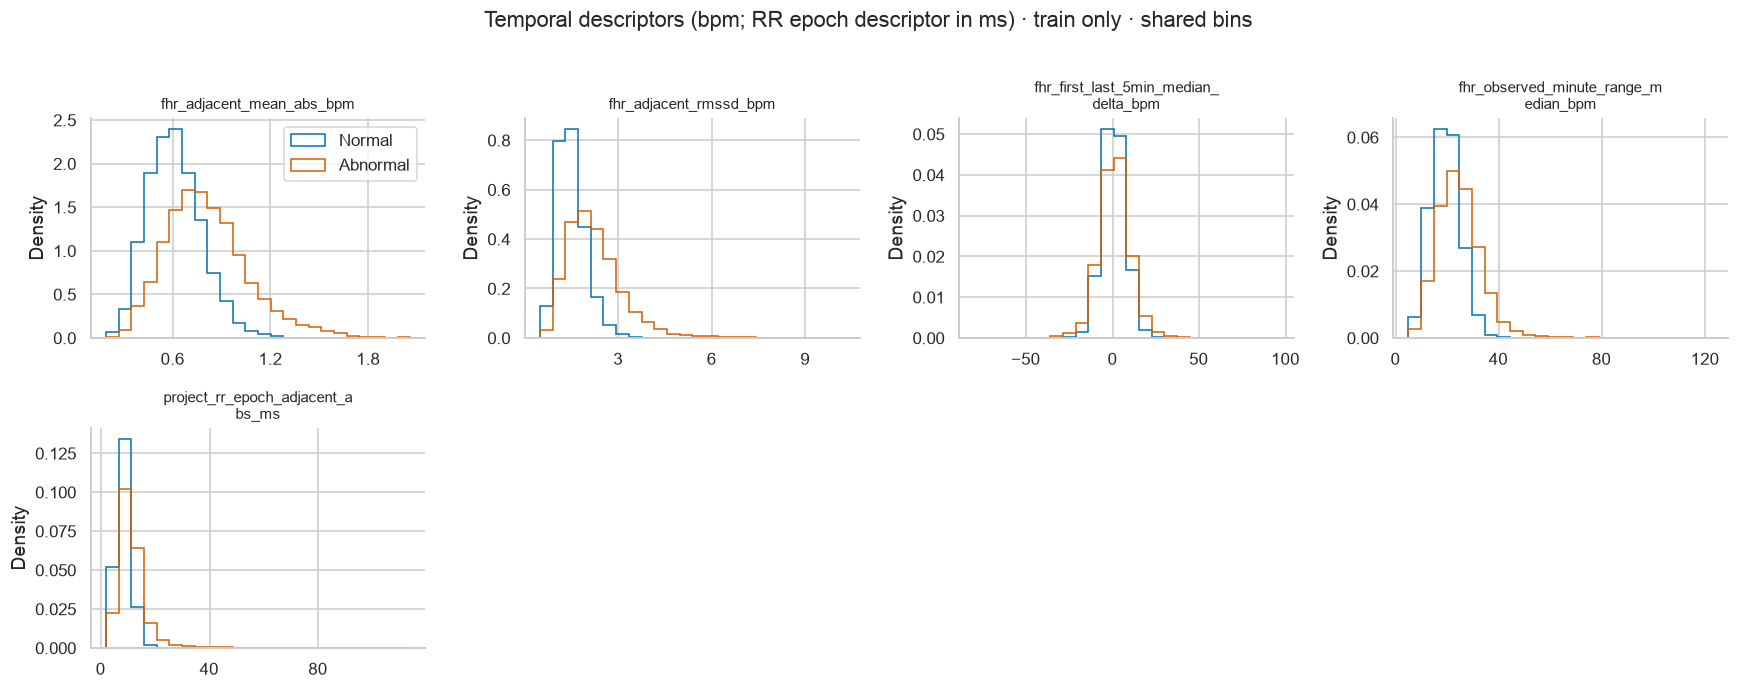

In [17]:
display(pd.read_csv(PROCESSED/'primary_feature_schema.csv'))
display(pd.read_csv(OUT/'train_feature_profile.csv')[['feature','missing','zero','min','median','max']].round(4))
def feature_distributions(names,filename,title):
    rows=int(np.ceil(len(names)/4));fig,axes=plt.subplots(rows,4,figsize=(16,3.1*rows));axes=np.array(axes).ravel()
    for ax,name in zip(axes,names):
        values=train[name].dropna();edges=np.histogram_bin_edges(values,bins=24)
        for label,color in [(0,'#0072b2'),(1,'#d55e00')]:
            ax.hist(train.loc[train.figo_label==label,name].dropna(),bins=edges,density=True,
                    histtype='step',color=color,label='Normal' if label==0 else 'Abnormal')
        ax.set_title(textwrap.fill(name,27),fontsize=10);ax.set_ylabel('Density');ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.ticklabel_format(axis='x',style='sci',scilimits=(-3,4),useMathText=True)
    for ax in axes[len(names):]:ax.axis('off')
    axes[0].legend();fig.suptitle(title+' · train only · shared bins',y=1.01)
    fig.tight_layout();show_save(filename)
feature_distributions([c for c in columns if c.startswith('fhr_bpm_')],'06a_fhr_train_distributions.png','FHR descriptors (bpm)')
feature_distributions([c for c in columns if c.startswith('uc_device_')],'06b_uc_train_distributions.png','UC descriptors (device units)')
feature_distributions([c for c in columns if not c.startswith(('fhr_bpm_','uc_device_'))],'06c_temporal_train_distributions.png','Temporal descriptors (bpm; RR epoch descriptor in ms)')


### Избыточность и чувствительность обработки

Детерминированные производные не являются независимыми измерениями. Корреляции ниже — описательная диагностика train, не выбор признаков по test. Состав признаков и пороги можно сравнивать дальше только внутри development CV.

Для 0/1/2 s заполнения показываем численное изменение доли пропусков и среднего FHR на train. Основные табличные признаки по-прежнему рассчитаны без такого заполнения. Малое изменение среднего само по себе не доказывает правильность восстановления краткой вариабельности.


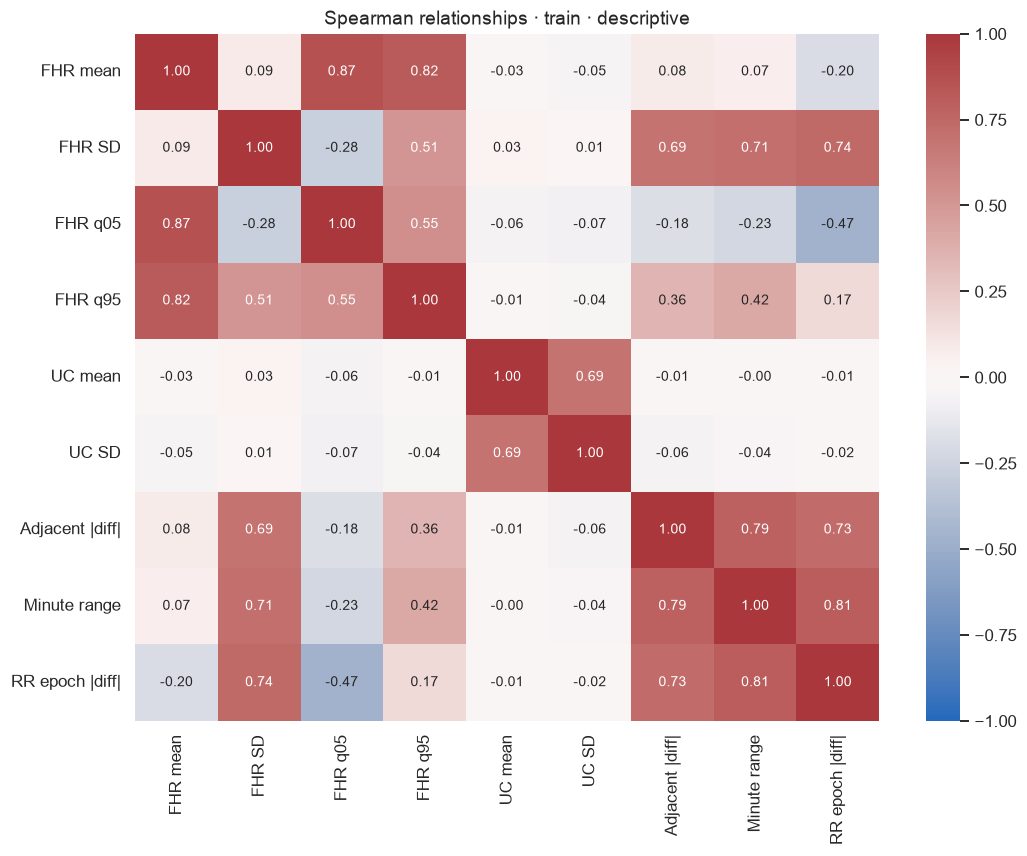

,max_gap_s,records,mean_filled_fraction,p95_filled_fraction,median_abs_mean_change_bpm,p95_abs_mean_change_bpm,mean_remaining_missing_fraction
0,0.0,12464,0.000000,0.000000,0.000000,0.000000,0.056845
1,1.0,12464,0.001111,0.004722,0.001392,0.048837,0.055734
2,2.0,12464,0.002663,0.011250,0.003687,0.085205,0.054182


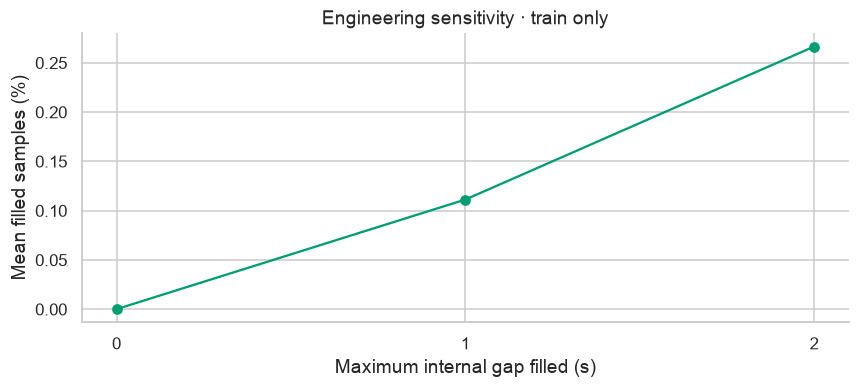

In [19]:
subset=['fhr_bpm_mean','fhr_bpm_std','fhr_bpm_q05','fhr_bpm_q95','uc_device_mean','uc_device_std',
        'fhr_adjacent_mean_abs_bpm','fhr_observed_minute_range_median_bpm','project_rr_epoch_adjacent_abs_ms']
labels=['FHR mean','FHR SD','FHR q05','FHR q95','UC mean','UC SD','Adjacent |diff|','Minute range','RR epoch |diff|']
corr=train[subset].corr(method='spearman')
fig,ax=plt.subplots(figsize=(10,8));sns.heatmap(corr,ax=ax,vmin=-1,vmax=1,cmap='vlag',center=0,
    xticklabels=labels,yticklabels=labels,annot=True,fmt='.2f',annot_kws={'size':9})
ax.set_title('Spearman relationships · train · descriptive');ax.grid(False);fig.tight_layout();show_save('07_train_correlations.png')
gap=pd.read_csv(OUT/'gap_sensitivity_train.csv');display(gap.round(6))
fig,ax=plt.subplots(figsize=(8,3.7));ax.plot(gap.max_gap_s,100*gap.mean_filled_fraction,marker='o',color='#009e73')
ax.set(xticks=[0,1,2],xlabel='Maximum internal gap filled (s)',ylabel='Mean filled samples (%)',title='Engineering sensitivity · train only')
fig.tight_layout();show_save('08_gap_sensitivity.png')


### Проверка происхождения опубликованных признаков

Mean/min/max/SD сверяются с собственными пересчётами. Для mean также проверяется вариант всех положительных FHR и линейное заполнение всех разрывов **только как диагностическая гипотеза происхождения**. Последний вариант не используется в подготовке и не экспортируется как способ восстановления сигналов.

Отличие может объясняться разными масками или предобработкой, не обязательно ошибкой авторов. Нет достаточного основания переносить опубликованные F_STV/F_LTV в поля больничного прибора; все 108 опубликованных признаков сохранены в отдельном файле, не в основном X.


,published,recomputed,rows,within_0_01_fraction,median_abs_error,max_abs_error
0,F_Mean,observed_mean,12464,0.37019,0.03652,50.49514
1,F_Mean,positive_source_mean,12464,0.37019,0.03653,50.49514
2,F_Mean,short_gap_mean,12464,0.39779,0.03385,50.49514
3,F_Mean,all_gap_linear_mean_audit_only,12464,0.51565,0.00736,34.00313
4,F_Min,observed_min,12464,0.89851,0.00000,103.00000
5,F_Max,observed_max,12464,0.90990,0.00000,91.00000
6,F_SD,observed_std,12464,0.39145,0.03556,26.30582


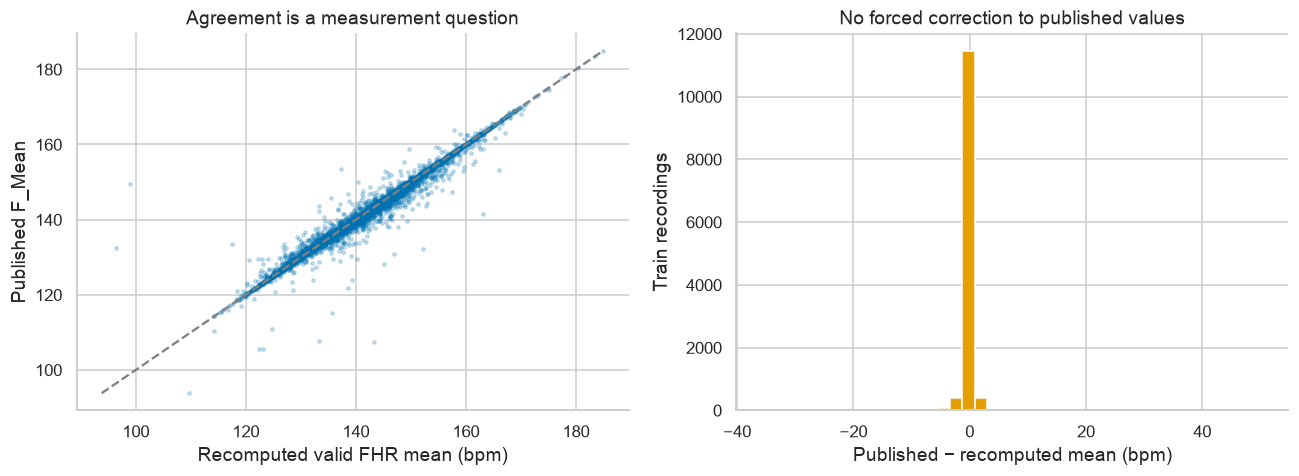

In [21]:
agreement=pd.read_csv(OUT/'published_feature_agreement_train.csv');display(agreement.round(5))
comparison=pd.read_parquet(OUT/'published_raw_comparison.parquet').merge(train[['record_id']],on='record_id',validate='one_to_one')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(comparison.observed_mean,comparison.F_Mean,s=5,alpha=.2,color='#0072b2')
limit=[min(comparison.observed_mean.min(),comparison.F_Mean.min()),max(comparison.observed_mean.max(),comparison.F_Mean.max())]
axes[0].plot(limit,limit,ls='--',color='grey');axes[0].set(xlabel='Recomputed valid FHR mean (bpm)',ylabel='Published F_Mean',title='Agreement is a measurement question')
axes[1].hist(comparison.F_Mean-comparison.observed_mean,bins=40,color='#e69f00')
axes[1].set(xlabel='Published − recomputed mean (bpm)',ylabel='Train recordings',title='No forced correction to published values')
fig.tight_layout();show_save('09_published_feature_agreement.png')


### Сохранённая подготовка: пропуски, скейлеры и маски

Для CatBoost сохранены исходные не масштабированные дескрипторы. Для линейных/дистанционных методов: median imputation → RobustScaler и отдельные индикаторы пропуска **всех** 27 полей. Статистики — только из пригодного train. Если пропуск впервые появляется в test или будущем вводе, его маска не теряется.

Сигнальный нормализатор использует train mean/std отдельно по FHR/UC; FHR-параметры не обучаются на нулях или диапазонных флагах, UC-ноль сохраняется. Метод transform_one возвращает values, observed_mask, used_mask, interpolated_mask. Все четыре нужны для корректного использования; preprocessing не выдаёт клиническое заключение.


In [23]:
parameters=json.loads((MODELS/'tabular_parameters.json').read_text())
display(pd.DataFrame({'feature':columns,'imputer_median':parameters['median_imputation'],
    'robust_center_after_imputation':parameters['robust_center'],'robust_scale':parameters['robust_scale']}).round(4))
display(pd.Series(json.loads((MODELS/'signal_normalization.json').read_text()),name='signal_normalization').to_frame())
print('Prepared matrix shapes:')
for split in ['train','validation','test']:
    print(split,np.load(PROCESSED/f'X_robust_{split}.npy',mmap_mode='r').shape)
normalizer=joblib.load(MODELS/'signal_normalizer_train.joblib')
example=normalizer.transform_one(signals[int(train.iloc[0].signal_row)])
assert np.isfinite(example['values']).all()
assert (example['values'][~example['used_mask']]==0).all()
print('Signal normalization returns separate masks:',list(example))


Prepared matrix shapes:
train (12464, 54)
validation (4165, 54)
test (4140, 54)
Signal normalization returns separate masks: ['values', 'observed_mask', 'used_mask', 'interpolated_mask']


,feature,imputer_median,robust_center_after_imputation,robust_scale
0,fhr_bpm_mean,141.0600,141.0600,10.4773
1,fhr_bpm_median,140.0000,140.0000,11.0000
2,fhr_bpm_std,8.1382,8.1382,3.9093
3,fhr_bpm_min,110.0000,110.0000,28.0000
4,fhr_bpm_max,176.0000,176.0000,33.0000
5,fhr_bpm_q05,130.9500,130.9500,11.0000
6,fhr_bpm_q25,136.0000,136.0000,11.0000
7,fhr_bpm_q75,145.0000,145.0000,11.0000
8,fhr_bpm_q95,156.0000,156.0000,13.0000
9,fhr_bpm_iqr,9.0000,9.0000,4.0000


,signal_normalization
channel_order,"[FHR, UC]"
fhr_validity,finite within provisional engineering envelope 30..240; original extremes retained separately
fit_split,train
gap_rule,bounded internal interpolation <=2 seconds; mask returned; no extrapolation
mask_required,True
mean,"[141.47109950208105, 31.08818292237199]"
missing_placeholder,0
observed_sample_count,"[84639476, 89740800]"
scale,"[12.497157540992605, 24.407923394319415]"
uc_validity,finite; zero retained


### Независимая проверка артефактов

Ниже отдельно пересчитываются параметры imputer/scaler и нормализации, проверяются все строки и границы patient_id/точных дублей, packed-маски, метки и roundtrip. Исходная неизвестность исхода сохраняется. Формат и исходные hashes контролируются. Проверка не является обучением или внешней клинической валидацией.


In [25]:
from tools.validate_jnu_preparation import validate
receipt=validate()
display(pd.Series(receipt,name='validation_receipt').to_frame())


,validation_receipt
passed,True
rows,20769
patients,12606
features,27
transformed_columns,54
metadata_source_preserved,True
nullable_outcome_preserved,True
apgar_domains_checked,True
patient_and_exact_duplicate_boundaries,True
source_hashes_checked,True


## Takeaways

1. Отдельная серия и первичный датасет готовы; исходный архив, все записи, ошибки формата и маски сохранены. Исправления не переписывают исходные данные.
2. FIGO binary и neonatal_asphyxia — разные постановки. Подозрительные/патологические классы не создаются искусственно. Клинические неизвестные метки не заменяются нулём; противоречивые положительные случаи требуют рассмотрения до обучения на исход.
3. Работа с пациентками и точными повторными сигналами учтена в разбиении. Доли abnormal близки; положительных пациенток по исходу 55/18/18. Это всё ещё только один центр и мало независимых редких исходов.
4. Значения за пределами инженерной маски сохранены и доступны для чувствительности; маска не доказывает клиническую норму. Широкий диапазон, короткая интерполяция и отсутствие сглаживания не заменяют проверку экстрактора на целевых устройствах. UC-пропуски по одному нулю не восстанавливаются.
5. Скейлеры и нормализатор обучены на train. Для следующей nested CV использовать необученный шаблон и повторный fit внутри фолдов; готовая масштабированная train-матрица для этого не подходит.
6. Случаи отказа из-за отсутствия FHR должны войти в отчёт о покрытии будущей модели. Нельзя сообщать только качество после исключения неудобных записей.

Следующий этап — ноутбук 02 по определениям событий и измерений, проверке published features и доступности входов из реальных отчётов. План обучения, метрики, калибровка, редкий клинический исход и внешняя проверка описаны в [ANALYSIS_PLAN.md](ANALYSIS_PLAN.md).

### Файлы

- `data/processed/jnu_ctg/v1/`: первичная/исходная/очищенная таблицы, 27 дескрипторов, качество, индексы, цели, разбиение, исходные сигналы и packed-маски, raw/scaled матрицы.
- `models/exported/jnu_ctg/preparation_v1/`: необученный шаблон, fitted pipeline, отдельные imputer/scaler/indicator, signal normalizer и JSON параметров.
- `research/experiments/jnu_ctg/preparation_v1/`: журнал нормализации, роли полей, контрольные таблицы, графики, manifest и независимый receipt.

Запуск из корня: `.venv/bin/python tools/execute_notebooks_inprocess.py research/notebooks/jnu_ctg/01_prepare_data.ipynb`. Для полного пересканирования сырья вызвать scan_signals(..., force=True); внешний источник должен остаться той же версии.
